# **Step 1: Machine Learning Models 📍**

In [ ]:

print("Plant Leaf Disease Detection Project")
print("GitHub Branch Update - Class 26")
print("Notebook update completed successfully!")


# - Task 1.1 — Load and Explore the Data 📂

In [ ]:
# 1) # Load image paths and labels into a DataFrame

import os
import pandas as pd

dataset_path = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"

data = []

for label in os.listdir(dataset_path):
    label_path = os.path.join(dataset_path, label)

    if os.path.isdir(label_path):
        for image in os.listdir(label_path):
            image_path = os.path.join(label_path, image)
            data.append([image_path, label])

df = pd.DataFrame(data, columns=["image_path", "label"])

df.head()

,image_path,label
0,/kaggle/input/datasets/emmarex/plantdisease/Pl...,Pepper__bell___Bacterial_spot
1,/kaggle/input/datasets/emmarex/plantdisease/Pl...,Pepper__bell___Bacterial_spot
2,/kaggle/input/datasets/emmarex/plantdisease/Pl...,Pepper__bell___Bacterial_spot
3,/kaggle/input/datasets/emmarex/plantdisease/Pl...,Pepper__bell___Bacterial_spot
4,/kaggle/input/datasets/emmarex/plantdisease/Pl...,Pepper__bell___Bacterial_spot


In [ ]:
# 2) Check the number of rows and columns
print(df.shape)

# 3) Check Missing Values
print(df.isnull().sum())

# 4) Check Class Balance
print(df["label"].value_counts())

(20639, 2)
image_path    0
label         0
dtype: int64
label
Tomato__Tomato_YellowLeaf__Curl_Virus          3209
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Tomato_Early_blight                            1000
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Pepper__bell___Bacterial_spot                   997
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Potato___healthy                                152
Name: count, dtype: int64


# -  Task 1.2 — Prepare the Data 🔖

In [ ]:
# 1) Read, resize, normalize images and store them with their labels

import cv2
import numpy as np

X = []
y = []

for path, label in zip(df["image_path"], df["label"]):

    img = cv2.imread(path)

    if img is not None:

        img = cv2.resize(img, (128, 128))
        img = img / 255.0

        X.append(img)
        y.append(label)

X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(20638, 128, 128, 3)
(20638,)


In [ ]:
# 2) Encode labels into numbers and split the dataset into training and testing sets

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split


encoder = LabelEncoder()
y = encoder.fit_transform(y)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16510, 128, 128, 3)
(4128, 128, 128, 3)
(16510,)
(4128,)


# -  Task 1.3 — Train and Compare Models 🔎

In [ ]:
# 1) Build, train, and test the CNN model for image classification

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping


cnn = Sequential()

cnn.add(Conv2D(32, (3,3), activation="relu", input_shape=(128,128,3)))
cnn.add(MaxPooling2D(2,2))

cnn.add(Conv2D(64, (3,3), activation="relu"))
cnn.add(MaxPooling2D(2,2))

cnn.add(Flatten())
cnn.add(Dense(128, activation="relu"))
cnn.add(Dropout(0.3))


cnn.add(Dense(len(np.unique(y_train)), activation="softmax"))

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(patience=3, restore_best_weights=True)

history = cnn.fit(
    X_train,y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop]
)

cnn_pred = cnn.predict(X_test)

cnn_pred = np.argmax(cnn_pred, axis=1)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 199s 423ms/step - accuracy: 0.4311 - loss: 1.8018 - val_accuracy: 0.7765 - val_loss: 0.6989
Epoch 2/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 199s 429ms/step - accuracy: 0.7617 - loss: 0.7211 - val_accuracy: 0.8128 - val_loss: 0.5483
Epoch 3/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 191s 410ms/step - accuracy: 0.8294 - loss: 0.5109 - val_accuracy: 0.8583 - val_loss: 0.4338
Epoch 4/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 187s 403ms/step - accuracy: 0.8812 - loss: 0.3362 - val_accuracy: 0.8807 - val_loss: 0.3560
Epoch 5/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 191s 412ms/step - accuracy: 0.9153 - loss: 0.2528 - val_accuracy: 0.8770 - val_loss: 0.4004
Epoch 6/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 187s 402ms/step - accuracy: 0.9402 - loss: 0.1802 - val_accuracy: 0.8879 - val_loss: 0.3582
Epoch 7/10
465/465 ━━━━━━━━━━━━━━━━━━━━ 187s 402ms/step - accuracy: 0.9417 - loss: 0.1732 - val_accuracy: 0.8849 - val_loss: 0.4110
129/129 ━━━━━━━━━━━━━━━━━━━━ 23s 179ms/step


In [ ]:
# 2) Reshape images and train the Random Forest model for image classification

# 📌 Reshape image data into 2D format because Random Forest and Decision Tree models cannot process 3D image inputs like CNN
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_flat, y_train)

rf_pred = rf.predict(X_test_flat)

In [ ]:
# 3) Train the Decision Tree model for image classification

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=5,
    random_state=42
)

dt.fit(X_train_flat, y_train)

dt_pred = dt.predict(X_test_flat)


In [ ]:
# 4) Compare CNN, Random Forest, and Decision Tree models using evaluation metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["CNN", "Random Forest", "Decision Tree"],

    "Accuracy": [
        accuracy_score(y_test, cnn_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, dt_pred)
    ],

     "Precision": [
        precision_score(y_test, cnn_pred, average="weighted", zero_division=0),
        precision_score(y_test, rf_pred, average="weighted", zero_division=0),
        precision_score(y_test, dt_pred, average="weighted", zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, cnn_pred, average="weighted", zero_division=0),
        recall_score(y_test, rf_pred, average="weighted", zero_division=0),
        recall_score(y_test, dt_pred, average="weighted", zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, cnn_pred, average="weighted", zero_division=0),
        f1_score(y_test, rf_pred, average="weighted", zero_division=0),
        f1_score(y_test, dt_pred, average="weighted", zero_division=0)
    ]
})


print(results)

           Model  Accuracy  Precision    Recall  F1-Score
0            CNN  0.872335   0.874476  0.872335  0.869927
1  Random Forest  0.688469   0.695725  0.688469  0.659250
2  Decision Tree  0.369671   0.378713  0.369671  0.372778


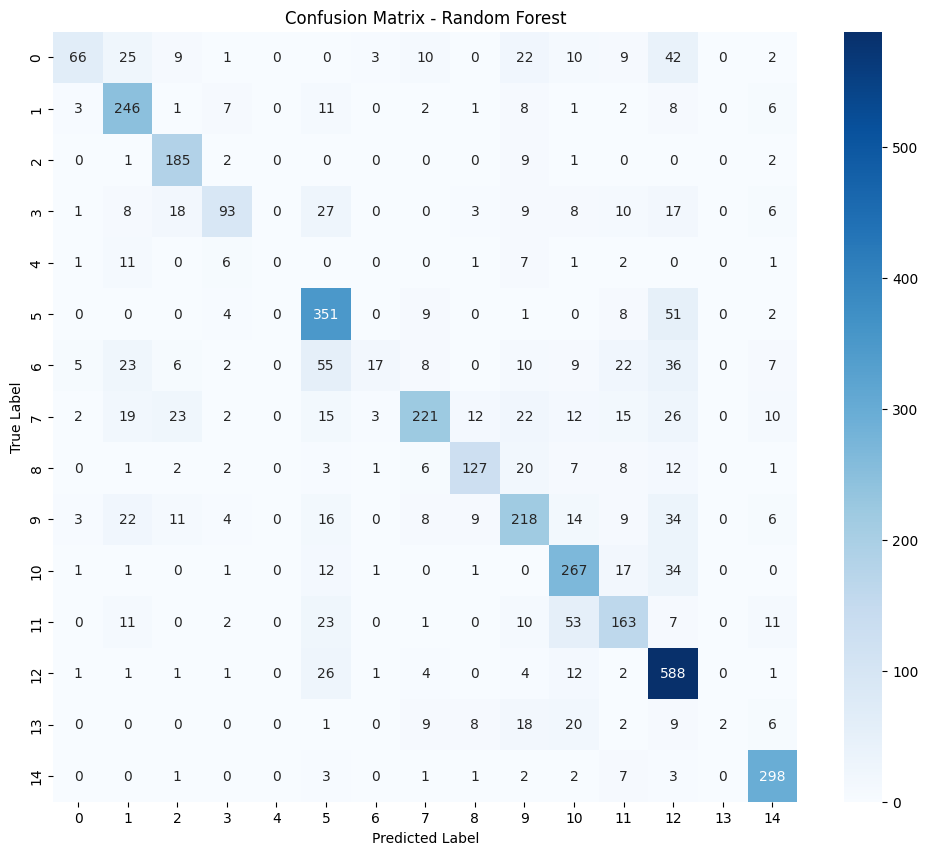

In [ ]:
# 5) Predict test data and display the Confusion Matrix for the Random Forest model

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

X_test_rf = X_test.reshape(X_test.shape[0], -1)
y_pred_rf = rf.predict(X_test_rf)


cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

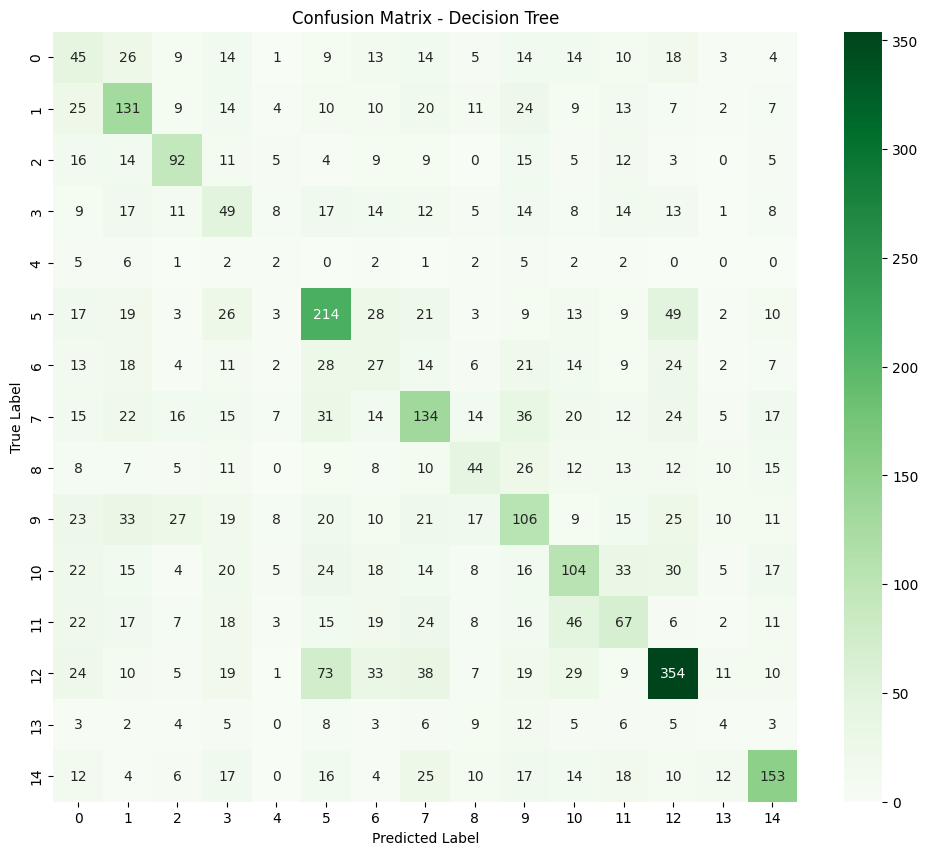

In [ ]:
# 6) Predict test data and display the Confusion Matrix for the Decision Tree model

X_test_flat = X_test.reshape(X_test.shape[0], -1)
y_pred_dt = dt.predict(X_test_flat)

cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

129/129 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step


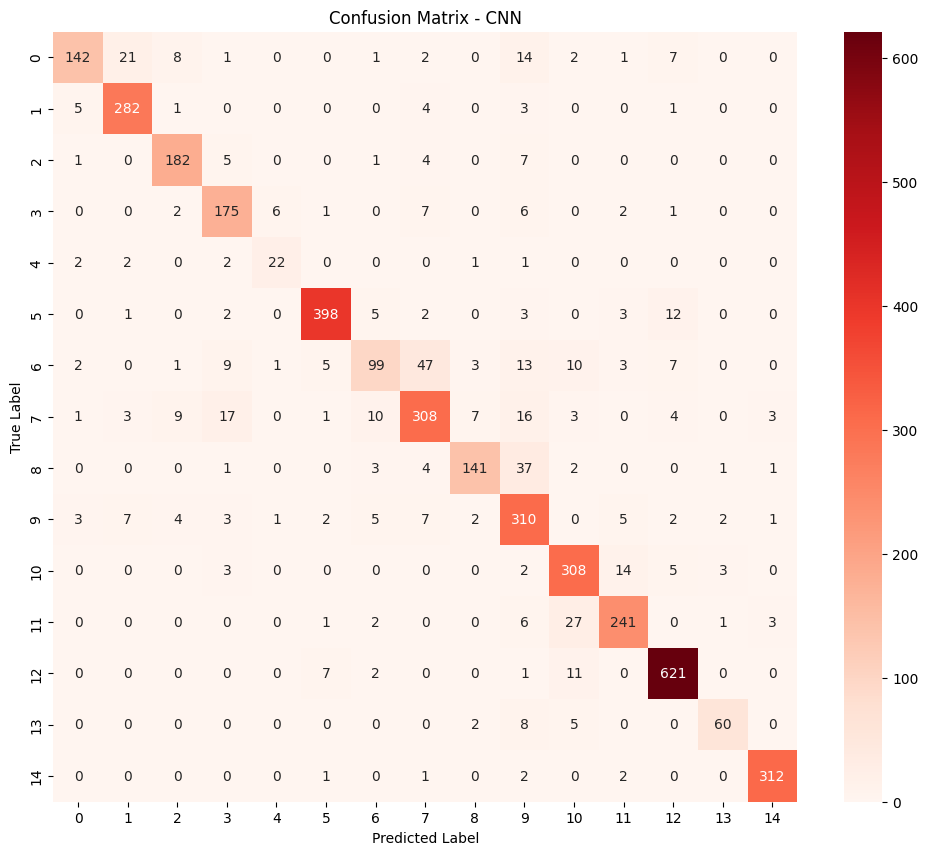

In [ ]:
# 7) Predict test data and display the Confusion Matrix for the CNN model

y_pred_cnn = cnn.predict(X_test)
y_pred_cnn_classes = np.argmax(y_pred_cnn, axis=1)

cm = confusion_matrix(y_test, y_pred_cnn_classes)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title("Confusion Matrix - CNN")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

In [ ]:
# 8) Create a summary table to compare the performance of all models
results = pd.DataFrame({
    "Model": ["CNN", "Random Forest", "Decision Tree"],
    "Accuracy": [0.872335, 0.688469, 0.369671],
    "Precision": [0.874476, 0.695725, 0.378713],
    "Recall": [0.872335, 0.688469, 0.369671],
    "F1-Score": [0.869927, 0.659250, 0.372778]
})
print(results)

           Model  Accuracy  Precision    Recall  F1-Score
0            CNN  0.872335   0.874476  0.872335  0.869927
1  Random Forest  0.688469   0.695725  0.688469  0.659250
2  Decision Tree  0.369671   0.378713  0.369671  0.372778


# **Best Model Selection and Explanation💡**

CNN achieved the best performance compared to Random Forest and Decision Tree.

It had the highest Accuracy, Precision, Recall, and F1-Score.

Therefore, CNN is the best model for image classification because it can learn image features more effectively than traditional machine learning models.

# **Step 2: Neural Network📍**

# - Task 2.1 — Build and Train 📂

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


233/233 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.4052 - loss: 1.9599 - val_accuracy: 0.7341 - val_loss: 0.8640 - learning_rate: 0.0010
Epoch 2/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6735 - loss: 1.0023 - val_accuracy: 0.7813 - val_loss: 0.6831 - learning_rate: 0.0010
Epoch 3/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7465 - loss: 0.7576 - val_accuracy: 0.8207 - val_loss: 0.5693 - learning_rate: 0.0010
Epoch 4/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7935 - loss: 0.6181 - val_accuracy: 0.8340 - val_loss: 0.5441 - learning_rate: 0.0010
Epoch 5/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8118 - loss: 0.5618 - val_accuracy: 0.8462 - val_loss: 0.4913 - learning_rate: 0.0010
Epoch 6/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8368 - loss: 0.4881 - val_accuracy: 0.8449 - val_loss: 0.4974 - learning_rate: 0.0010
Epoch 7/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8550 - loss: 0.4337 - val_accurac

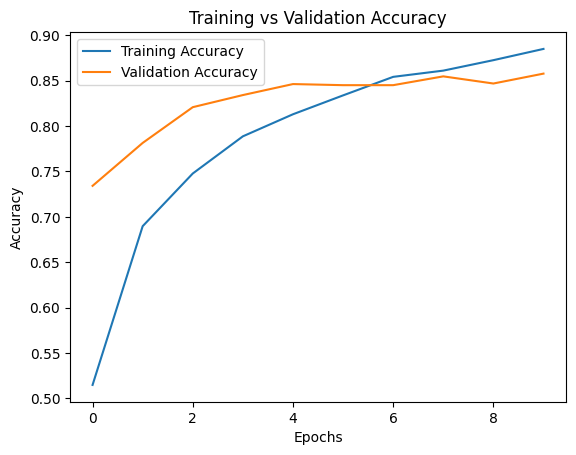

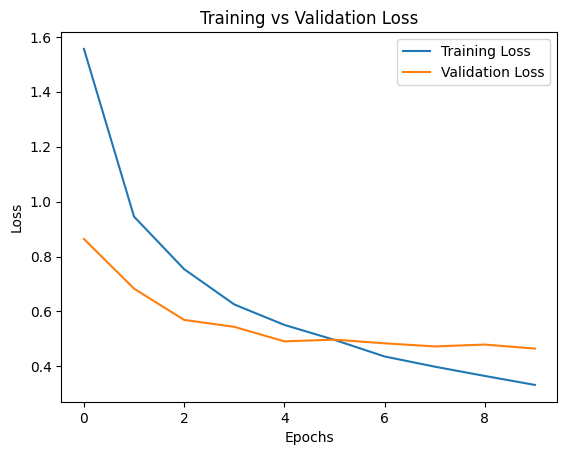

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.decomposition import PCA


pca = PCA(n_components=200)
X_train_pca = pca.fit_transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)


nn = Sequential()

nn.add(Dense(512, activation="relu", input_shape=(X_train_pca.shape[1],)))
nn.add(BatchNormalization())
nn.add(Dropout(0.3))

nn.add(Dense(256, activation="relu"))
nn.add(BatchNormalization())
nn.add(Dropout(0.3))

nn.add(Dense(128, activation="relu"))
nn.add(Dropout(0.2))

nn.add(Dense(len(np.unique(y_train)), activation="softmax"))

nn.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)

history_nn = nn.fit(
    X_train_pca,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr]
)

# Plot training and validation accuracy
plt.plot(history_nn.history["accuracy"], label="Training Accuracy")
plt.plot(history_nn.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history_nn.history["loss"], label="Training Loss")
plt.plot(history_nn.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# **Training and Validation Curves Analysis📉**

The training accuracy increased steadily from 51% to 88% across 10 epochs, indicating that the model learned effectively from the training data.

The validation accuracy followed a similar trend, reaching 86% by the end of training and staying close to the training accuracy, which shows good generalization with minimal overfitting.

In the loss graph, both training and validation loss decreased consistently throughout training, confirming stable learning. The use of PCA, BatchNormalization, and Dropout contributed to the model's improved performance.


# - Task 2.2 — Compare with Step 1 📝

In [ ]:
# Predict using Neural Network
nn_pred = nn.predict(X_test_pca)

nn_pred = np.argmax(nn_pred, axis=1)

# Add Neural Network results to comparison table
results = pd.DataFrame({
    "Model": ["CNN", "Random Forest", "Decision Tree", "Neural Network"],

    "Accuracy": [
        accuracy_score(y_test, cnn_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, nn_pred)
    ],

    "Precision": [
        precision_score(y_test, cnn_pred, average="weighted", zero_division=0),
        precision_score(y_test, rf_pred, average="weighted", zero_division=0),
        precision_score(y_test, dt_pred, average="weighted", zero_division=0),
        precision_score(y_test, nn_pred, average="weighted", zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, cnn_pred, average="weighted", zero_division=0),
        recall_score(y_test, rf_pred, average="weighted", zero_division=0),
        recall_score(y_test, dt_pred, average="weighted", zero_division=0),
        recall_score(y_test, nn_pred, average="weighted", zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, cnn_pred, average="weighted", zero_division=0),
        f1_score(y_test, rf_pred, average="weighted", zero_division=0),
        f1_score(y_test, dt_pred, average="weighted", zero_division=0),
        f1_score(y_test, nn_pred, average="weighted", zero_division=0)
    ]
})

print(results)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
            Model  Accuracy  Precision    Recall  F1-Score
0             CNN  0.872335   0.874476  0.872335  0.869927
1   Random Forest  0.688469   0.695725  0.688469  0.659250
2   Decision Tree  0.369671   0.378713  0.369671  0.372778
3  Neural Network  0.842781   0.841349  0.842781  0.840738


# **Neural Network Evaluation and Model Comparison💡**

The Neural Network achieved strong performance after applying PCA for dimensionality reduction, which helped reduce overfitting and improved generalization on the test set.

The model reached a validation accuracy of 86%, which is comparable to the CNN's accuracy of 87%, showing that a well-optimized Dense network can compete with CNN when the input features are properly preprocessed.

However, CNN still achieved the best overall performance because it is specifically designed for image classification tasks and can extract spatial features directly from images.